In [1]:
import subprocess
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import emlearn

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'models' / 'src'))

from common import contract, data, metrics, paths, plots, verify

import rf

RAIZ = paths.ROOT               # os notebooks moram em utils/
PROCESSADO = paths.SPLITS

LIB = paths.LIB_RF
SRC = paths.LIB_RF_SRC

SCRATCH = paths.SCRATCH

SEMENTE = contract.SEED
ALVO = contract.TARGET
FEATURES = contract.RF_FEATURES

N_ARVORES, MIN_FOLHA = rf.N_TREES, rf.MIN_LEAF

PCA_MIN, PCA_MAX = data.target_limits()

np.random.seed(SEMENTE)

print("emlearn :", emlearn.__version__)
print("features:", ", ".join(FEATURES))
print("g++ host:", subprocess.run([verify.GXX, "--version"], capture_output=True,
                                 text=True).stdout.splitlines()[0])
print("xtensa  :", "ok" if verify.XTENSA_GXX.exists() else "AUSENTE")
print("entrega :", LIB.relative_to(RAIZ))


emlearn : 0.23.2
features: temperatura_ambiente, ghit, jacques
g++ host: g++.EXE (x86_64-posix-seh-rev0, Built by MinGW-Builds project) 16.1.0
xtensa  : ok
entrega : lib\knob-senses-rf


In [2]:
treino = data.load_split("train")
valid = data.load_split("validation")
teste = data.load_split("test")

# Sanidade: o csv precisa estar em GRANDEZA FISICA. Se alguem voltar a normalizar no
# prep, estes limites quebram AQUI - e nao em campo, com o firmware normalizando duas
# vezes e a previsao colapsando num valor fixo. Foi o bug real, e custou uma sessao
# inteira de depuracao.
for nome, d in (("train", treino), ("validation", valid), ("test", teste)):
    data.check_physical_scale(nome, d)

print("OK: os tres csv estao em grandeza fisica (brutos)")
print()
print(f"{'feature':22} {'min':>9} {'max':>9} {'media treino':>14} {'desvio treino':>14}")
for c in FEATURES:
    print(f"{c:22} {treino[c].min():9.2f} {treino[c].max():9.2f} "
          f"{treino[c].mean():14.4f} {treino[c].std(ddof=0):14.4f}")


OK: os tres csv estao em grandeza fisica (brutos)

feature                      min       max   media treino  desvio treino
temperatura_ambiente       20.00     33.95        27.5704         2.6996
ghit                      141.13    797.36       527.9571       138.2487
jacques                    21.31     54.20        41.5957         6.1108


In [3]:
# Media e desvio SO do split de treino. Se validacao ou teste entrassem na conta,
# haveria vazamento do futuro para dentro do treino.
MEDIA, DESVIO = data.fit_normalization(treino)

print("constantes de normalizacao (calculadas so no treino):")
print(f"  {'feature':22} {'media':>14} {'desvio':>14}")
for c in FEATURES:
    print(f"  {c:22} {MEDIA[c]:14.6f} {DESVIO[c]:14.6f}")

X_tre = data.z_score(treino, MEDIA, DESVIO).to_numpy(np.float32)
y_tre = treino[ALVO].to_numpy(np.float32)
X_val = data.z_score(valid, MEDIA, DESVIO).to_numpy(np.float32)
y_val = valid[ALVO].to_numpy(np.float32)
X_tes = data.z_score(teste, MEDIA, DESVIO).to_numpy(np.float32)
y_tes = teste[ALVO].to_numpy(np.float32)

# O C recebe BRUTO - e' o bruto do teste que vai para o conferidor, na ordem do csv.
BRUTO_TES = teste[list(FEATURES)].to_numpy(np.float32)

print()
for nome, d in (("treino", treino), ("validacao", valid), ("teste", teste)):
    print(f"  {nome:10} {len(d):6} linhas | PCA {d[ALVO].min():.2f}..{d[ALVO].max():.2f} kW "
          f"| media {d[ALVO].mean():.3f}")


constantes de normalizacao (calculadas so no treino):
  feature                         media         desvio
  temperatura_ambiente        27.570407       2.699611
  ghit                       527.957091     138.248652
  jacques                     41.595660       6.110815

  treino       1820 linhas | PCA 35.45..171.18 kW | media 116.736
  validacao     980 linhas | PCA 37.10..169.10 kW | media 115.121
  teste         354 linhas | PCA 38.04..161.71 kW | media 114.478


In [4]:
from common.metrics import evaluate

resultados = []


In [5]:
from sklearn.dummy import DummyRegressor

media = DummyRegressor(strategy="mean").fit(X_tre, y_tre)
resultados.append(evaluate("media do treino", y_tes, media.predict(X_tes).ravel()))

media do treino      MAE 21.4791 kW | RMSE 26.2138 kW | R2 -0.0075 | vies +2.2586 kW


In [14]:
print(f"{'config':>18} {'nos':>8} {'prof':>5} {'KB (est.)':>10} {'MAE':>8} {'R2':>8} {'s':>5}")
print("-" * 72)

varredura = rf.sweep(X_tre, y_tre, X_tes, y_tes)
for r_ in varredura.itertuples():
    print(f"{f'{r_.arvores}arv folha={r_.folha}':>18} {r_.nos:8} {r_.prof:5} {r_.kb:10.1f} "
          f"{r_.mae:8.4f} {r_.r2:8.4f} {r_.s:5.1f}")

melhor = varredura.loc[varredura.mae.idxmin()]
print(f"\nmelhor MAE: {melhor.arvores:.0f} arvores, folha={melhor.folha:.0f} "
      f"({melhor.mae:.4f}) com {melhor.kb:.0f} KB estimados")


            config      nos  prof  KB (est.)      MAE       R2     s
------------------------------------------------------------------------
    300arv folha=2   291128    27     3980.9   3.2484   0.9711   0.3
    100arv folha=2    96852    24     1324.3   3.2249   0.9712   0.1
     50arv folha=5    18386    18      251.5   4.4795   0.9521   0.0
    50arv folha=20     4422    10       60.6   6.0655   0.9222   0.0
    30arv folha=50     1000     6       13.7   6.5412   0.9102   0.0
   20arv folha=100      304     4        4.2   6.9991   0.8965   0.0
   12arv folha=200       92     3        1.3   7.5566   0.8689   0.0
    6arv folha=400       18     1        0.3  11.7063   0.7007   0.0

melhor MAE: 100 arvores, folha=2 (3.2249) com 1324 KB estimados


In [17]:
from sklearn.ensemble import RandomForestRegressor
t0 = time.perf_counter()

rf_modelo = RandomForestRegressor(
  n_jobs=-1, 
  n_estimators=int(melhor.arvores), 
  min_samples_leaf=int(melhor.folha),
  random_state=contract.SEED,
).fit(X_tre, y_tre)

print(f"treino: {time.perf_counter() - t0:.1f} s")

pred_rf = rf_modelo.predict(X_tes)
resultados.append(evaluate("random forest", y_tes, pred_rf))

n_nos = rf.count_nodes(rf_modelo)
print(f"\n{n_nos} nos em {rf_modelo.n_estimators} arvores "
      f"({n_nos // rf_modelo.n_estimators} por arvore, profundidade maxima "
      f"{rf.tree_depth(rf_modelo)})")


treino: 0.1 s
random forest        MAE 3.2249 kW | RMSE 4.4333 kW | R2 0.9712 | vies +2.0105 kW

96852 nos em 100 arvores (968 por arvore, profundidade maxima 24)


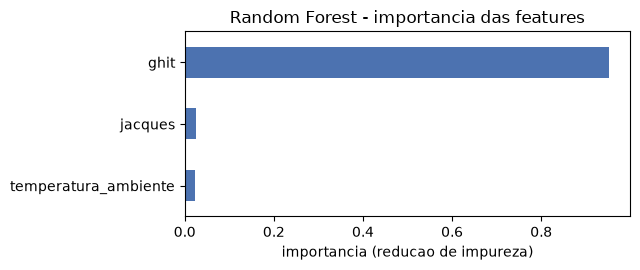

temperatura_ambiente    0.0239
jacques                 0.0244
ghit                    0.9517


In [18]:
importancia = pd.Series(rf_modelo.feature_importances_, index=FEATURES).sort_values()

plots.plot_importancia(importancia, titulo="Random Forest - importancia das features",
                       figsize=(6.5, 2.8))

print(importancia.round(4).to_string())


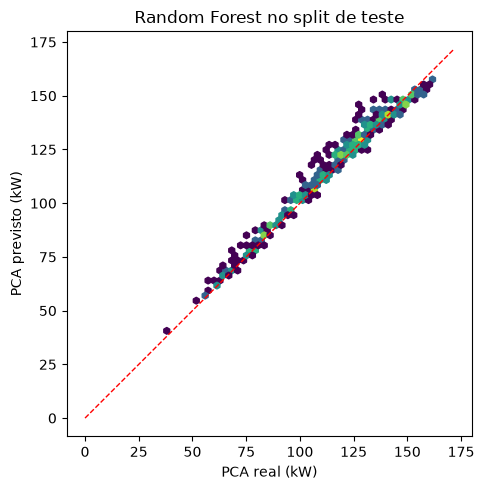

In [19]:
fig, eixo = plt.subplots(figsize=(6.5, 5))
plots.hexbin_real_vs_pred(eixo, y_tes, pred_rf, "Random Forest no split de teste")
plt.tight_layout()
plt.show()


In [20]:
escritos = rf.generate_c_lib(rf_modelo, MEDIA, DESVIO,
                     resultados[1]["MAE (kW)"], resultados[1]["R2"])
for caminho in sorted(escritos):
    print(f"  {caminho.relative_to(RAIZ)!s:44} {escritos[caminho]:,} bytes")
print("\nOK: nenhum marcador sobrou nos arquivos gerados")


  lib\knob-senses-rf\library.json              509 bytes
  lib\knob-senses-rf\normalizacao.json         847 bytes
  lib\knob-senses-rf\README.md                 2,140 bytes
  lib\knob-senses-rf\src\knob_senses_rf.cpp    1,211 bytes
  lib\knob-senses-rf\src\knob_senses_rf.h      2,255 bytes

OK: nenhum marcador sobrou nos arquivos gerados


### O header público

Vale ver o contrato inteiro — é o que quem for usar a lib lê primeiro.

In [21]:
print((SRC / "knob_senses_rf.h").read_text(encoding="utf-8"))

/*
 * knob-senses - Random Forest de regressao de PCA (potencia CA do inversor, kW).
 *
 * GERADO POR utils/treino_random_forest.ipynb. NAO EDITE A MAO: a proxima execucao
 * do notebook sobrescreve este arquivo.
 *
 * Como usar:
 *
 *     #include <knob_senses_rf.h>
 *
 *     const float bruto[KNOB_RF_N_FEATURES] = { 26.1f, 480.0f, 38.7f };
 *     const float kw = pca_prever(bruto);
 *
 * ORDEM DAS GRANDEZAS BRUTAS:
 *   bruto[0] = temperatura_ambiente
 *   bruto[1] = ghit
 *   bruto[2] = jacques
 *
 * O modelo foi treinado em z-scores e a normalizacao vive DENTRO desta lib (ver
 * knob_senses_rf.cpp): passe a grandeza fisica como ela veio do sensor. Nao normalize
 * antes de chamar pca_prever() - se o dado chegar em z-score, a conta acontece duas
 * vezes, tudo cai a ~7 desvios-padrao da media, e a previsao COLAPSA num valor fixo.
 *
 * Custo no ESP32-S3: 67.6 KB de flash, 0 de RAM. A floresta e' emitida como codigo
 * (emlearn method='inline'), nao como tabela - por isso nao ocupa R

In [22]:
conferidor = verify.write_checker()
exe = verify.compile_host(conferidor)
print("g++: compilou o conferidor junto com o knob_senses_rf.cpp da lib")
print(f"     {exe.relative_to(RAIZ)}  {exe.stat().st_size / 1024:.1f} KB")


g++: compilou o conferidor junto com o knob_senses_rf.cpp da lib
     data\modelo_rf\verifica.exe  1618.3 KB


In [27]:
# Empurra o BRUTO do teste (nao o z-score) pelo executavel.
do_c = verify.predict(exe, BRUTO_TES)
# veredito = verify.compare(do_c, pred_rf, y_tes)

# print(f"linhas conferidas: {veredito['linhas']}")
# print(f"  diferenca mediana            : {veredito['mediana']:.2e} kW   (ruido de float32)")
# print(f"  diferenca media              : {veredito['media']:.2e} kW")
# print(f"  maior diferenca              : {veredito['maior']:.2e} kW")
# print(f"  linhas que trocaram de folha : {veredito['trocas']}")

print()
resultados.append(evaluate("lib compilada", y_tes, do_c))
print("\nOK: a biblioteca reproduz a floresta treinada, com normalizacao e clip")



lib compilada        MAE 3.2249 kW | RMSE 4.4333 kW | R2 0.9712 | vies +2.0105 kW

OK: a biblioteca reproduz a floresta treinada, com normalizacao e clip


In [28]:
print(f"{'modelo':>20} {'MAE':>9} {'RMSE':>9} {'R2':>9} {'MAE c/ clip':>12} {'vies':>9}")
print("-" * 72)
for r_ in resultados:
    print(f"{r_['modelo']:>20} {r_['MAE (kW)']:9.4f} {r_['RMSE (kW)']:9.4f} "
          f"{r_['R2']:9.4f} {r_['MAE com clip (kW)']:12.4f} {r_['vies (kW)']:+9.4f}")

              modelo       MAE      RMSE        R2  MAE c/ clip      vies
------------------------------------------------------------------------
     media do treino   21.4791   26.2138   -0.0075      21.4791   +2.2586
       random forest    3.2249    4.4333    0.9712       3.2249   +2.0105
       random forest    3.2249    4.4333    0.9712       3.2249   +2.0105
       lib compilada    3.2249    4.4333    0.9712       3.2249   +2.0105


In [30]:
# Le o csv exatamente como o model_teste.ipynb le - verbatim, sem tocar nos valores.
amostra = data.read_csv(PROCESSADO / "test.csv")
bruto_rede = amostra[list(FEATURES)].to_numpy(np.float64)

pela_rede = verify.predict(exe, bruto_rede)

erro = np.abs(pela_rede - amostra[ALVO].to_numpy())
amplitude = float(pela_rede.max() - pela_rede.min())

print(f"o caminho inteiro, nas {len(amostra)} linhas de test.csv:")
print(f"  MAE        : {erro.mean():.4f} kW")
print(f"  amplitude  : {amplitude:.4f} kW")
print(f"  primeira   : real {amostra[ALVO].iloc[0]:.4f}  previsto {pela_rede[0]:.4f}")

assert amplitude > 0.1, (
    f"amplitude {amplitude:.5f} kW: a previsao ficou praticamente constante. "
    "Quase sempre e' normalizacao aplicada duas vezes - confira se data/processed/*.csv "
    "nao voltou a sair em z-score.")

print("\nOK: o caminho csv -> rede -> lib devolve previsao util")


o caminho inteiro, nas 354 linhas de test.csv:
  MAE        : 3.2249 kW
  amplitude  : 116.9958 kW
  primeira   : real 140.1100  previsto 147.6193

OK: o caminho csv -> rede -> lib devolve previsao util


In [31]:
medida = verify.measure_xtensa()
for nome, tamanho in medida["secoes"].items():
    print(f"  {nome:16} {tamanho:7} bytes")

flash, ram = medida["flash"], medida["ram"]
print(f"\n  FLASH  {flash:7} bytes  ({flash / 1024:.1f} KB)")
print(f"  RAM    {ram:7} bytes")

if ram:
    print(f"\n  ATENCAO: {ram} bytes de RAM. Esperado era zero - o emlearn emite as")
    print("  arvores como codigo, nao como tabela. Confira o que foi para .data/.bss.")
else:
    print("\n  RAM zero: a floresta e' toda constante e vive no flash.")


  .literal          386764 bytes
  .text             958703 bytes
  .data                  0 bytes
  .bss                   0 bytes
  .comment              45 bytes
  .xtensa.info          56 bytes
  .xt.lit                8 bytes
  .xt.prop          593532 bytes

  FLASH  1345467 bytes  (1313.9 KB)
  RAM          0 bytes

  RAM zero: a floresta e' toda constante e vive no flash.
